# Feature Extraction & Selection — Ovarian Cancer Dataset
**Authors:** First Student; Second Student; Third Student

---
### Report Structure
1. **Step 1 – Feature Extraction** — PCA (dimensionality reduction)
2. **Step 2 – Feature Selection** — Filter, Wrapper, and Embedded methods
3. **Step 3 – Top Features Deduction & Comparison** (common features across methods)
4. **Step 4 – Smart Feature Combinations** (best performance with minimum features)

---
## 0. Imports & Model Definitions

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from scipy.io import arff

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score

# Feature Selection
from sklearn.feature_selection import (
    SelectKBest, chi2, mutual_info_classif,
    RFE, SelectFromModel, f_classif
)

# Models
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier,
    ExtraTreesClassifier, AdaBoostClassifier
)
from sklearn.naive_bayes import GaussianNB

from imblearn.over_sampling import SMOTE
from joblib import Parallel, delayed   # ← added

# ─────────────────────────────────────────
# Unified model dictionary (all 10 models)
# ─────────────────────────────────────────
models = {
    "Linear SVM"         : SVC(kernel='linear', C=0.05, random_state=42),
    "RBF SVM"            : SVC(kernel='rbf',    C=1.0,  random_state=42),
    "Logistic Regression": LogisticRegression(C=0.05, solver='liblinear', random_state=42, n_jobs=-1),
    "Random Forest"      : RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting"  : GradientBoostingClassifier(random_state=42),
    "Extra Trees"        : ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "KNN"                : KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "AdaBoost"           : AdaBoostClassifier(random_state=42),
    "Ridge"              : RidgeClassifier(),
    "Naive Bayes"        : GaussianNB()
}

K_FEATURES = 25
POS_LABEL   = "Cancer"

print(f"Models loaded: {list(models.keys())}")

Models loaded: ['Linear SVM', 'RBF SVM', 'Logistic Regression', 'Random Forest', 'Gradient Boosting', 'Extra Trees', 'KNN', 'AdaBoost', 'Ridge', 'Naive Bayes']


---
## 1. Data Loading & Preprocessing

In [9]:
# ── 1.1 Load ARFF ──────────────────────────────────────────────────────────
data, meta = arff.loadarff("/kaggle/input/datasets/djalilbouchama/ovariann/Ovarian.arff")
df = pd.DataFrame(data)

# Decode byte-strings
for col in df.select_dtypes([object]):
    df[col] = df[col].str.decode("utf-8")

print("Dataset shape:", df.shape)
print("Classes:", df["Class"].unique())
print("Class distribution:\n", df["Class"].value_counts())

Dataset shape: (253, 15155)
Classes: ['Normal' 'Cancer']
Class distribution:
 Class
Cancer    162
Normal     91
Name: count, dtype: int64


In [29]:
df.head()

,MZ-7.86E-05,MZ2.18E-07,MZ9.60E-05,MZ0.000366014,MZ0.000810195,MZ0.001428564,MZ0.002221123,MZ0.003187869,MZ0.004328805,MZ0.005643929,...,MZ19974.404,MZ19977.042,MZ19979.68,MZ19982.319,MZ19984.957,MZ19987.596,MZ19990.235,MZ19992.874,MZ19995.513,Class
0,0.494626,0.263735,0.321841,0.220934,0.297622,0.316458,0.154763,0.223685,0.304346,0.241757,...,0.483622,0.449296,0.449296,0.449296,0.449296,0.449296,0.449296,0.449296,0.449296,Normal
1,0.258063,0.406593,0.321841,0.069771,0.333335,0.354432,0.321431,0.144740,0.260869,0.142853,...,0.631765,0.619718,0.619718,0.619718,0.619718,0.619718,0.619718,0.619718,0.619718,Normal
2,0.537636,0.032966,0.321841,0.209307,0.404762,0.113927,0.369049,0.223685,0.536231,0.131865,...,0.038462,0.035918,0.035918,0.035918,0.035918,0.035918,0.035918,0.035918,0.035918,Normal
3,0.000000,0.395605,0.310347,0.197673,0.404762,0.455701,0.416666,0.210527,0.420292,0.274723,...,0.497864,0.486621,0.486621,0.486621,0.486621,0.486621,0.486621,0.486621,0.486621,Normal
4,0.526884,0.395605,0.367817,0.383719,0.488099,0.392405,0.238094,0.500000,0.362316,0.274723,...,0.267096,0.251408,0.251408,0.251408,0.251408,0.251408,0.251408,0.251408,0.251408,Normal


In [10]:
# ── 1.2 Split X / y ────────────────────────────────────────────────────────
X = df.drop("Class", axis=1).apply(pd.to_numeric, errors='coerce')
y = df["Class"]

# ── 1.3 Train / Test split (stratified) ───────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ── 1.4 Impute missing values (train statistics only) ─────────────────────
train_mean = X_train.mean()
X_train = X_train.fillna(train_mean)
X_test  = X_test.fillna(train_mean)

# ── 1.5 Standardisation ───────────────────────────────────────────────────
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("Train size:", X_train_scaled.shape)
print("Test  size:", X_test_scaled.shape)

Train size: (202, 15154)
Test  size: (51, 15154)


In [11]:
# ── 1.6 Outlier Removal (IQR on training set) ─────────────────────────────
Q1 = np.percentile(X_train_scaled, 25, axis=0)
Q3 = np.percentile(X_train_scaled, 75, axis=0)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

valid = (X_train_scaled >= lower) & (X_train_scaled <= upper)
mask  = valid.mean(axis=1) > 0.9

X_train_clean = X_train_scaled[mask]
y_train_clean = y_train.iloc[mask]

print("Before outlier removal:", X_train_scaled.shape)
print("After  outlier removal:", X_train_clean.shape)

Before outlier removal: (202, 15154)
After  outlier removal: (195, 15154)


In [12]:
# ── 1.7 SMOTE Balancing ───────────────────────────────────────────────────
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_clean, y_train_clean)

print("Before SMOTE:\n", y_train_clean.value_counts())
print("After  SMOTE:\n", pd.Series(y_train_balanced).value_counts())

Before SMOTE:
 Class
Cancer    125
Normal     70
Name: count, dtype: int64
After  SMOTE:
 Class
Cancer    125
Normal    125
Name: count, dtype: int64


---
## 2. Baseline — Raw Data (No Feature Engineering)

In [34]:
# Utility: evaluate all models and return a results DataFrame
def _fit_eval(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    acc = accuracy_score(y_te, y_pred)
    f1  = f1_score(y_te, y_pred, pos_label=POS_LABEL, average='binary')
    return {"Model": name, "Accuracy": acc, "F1": f1}

def evaluate_models(X_tr, y_tr, X_te, y_te, label=""):
    rows = Parallel(n_jobs=-1)(
        delayed(_fit_eval)(name, model, X_tr, y_tr, X_te, y_te)
        for name, model in models.items()
    )
    for r in rows:
        print(f"  {r['Model']:25s}: Acc={r['Accuracy']:.4f}  F1={r['F1']:.4f}")
    return pd.DataFrame(rows).set_index("Model")

print("=" * 60)
print("BASELINE — Raw Scaled Data")
print("=" * 60)
results_raw = evaluate_models(X_train_scaled, y_train, X_test_scaled, y_test, label="Raw")

BASELINE — Raw Scaled Data


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1271: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 4.
  warnings.warn(


  Linear SVM               : Acc=1.0000  F1=1.0000
  RBF SVM                  : Acc=1.0000  F1=1.0000
  Logistic Regression      : Acc=1.0000  F1=1.0000
  Random Forest            : Acc=0.9804  F1=0.9851
  Gradient Boosting        : Acc=0.9804  F1=0.9851
  Extra Trees              : Acc=0.9804  F1=0.9851
  KNN                      : Acc=0.8824  F1=0.9143
  AdaBoost                 : Acc=1.0000  F1=1.0000
  Ridge                    : Acc=1.0000  F1=1.0000
  Naive Bayes              : Acc=0.8627  F1=0.8923


---
## STEP 1 — Feature Extraction: PCA

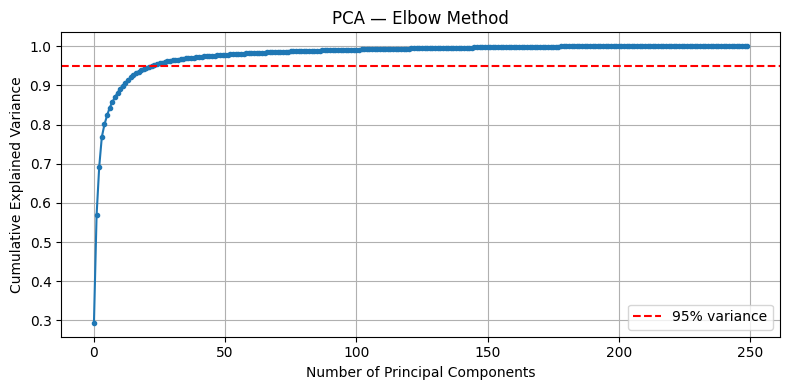

Optimal number of PCA components (95% variance): 23


In [14]:
# ── PCA Elbow Plot ─────────────────────────────────────────────────────────
pca_temp = PCA().fit(X_train_balanced)
cum_var  = np.cumsum(pca_temp.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(cum_var, marker='o', markersize=3)
plt.axhline(0.95, color='red', linestyle='--', label='95% variance')
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA — Elbow Method")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

n_components = int(np.argmax(cum_var >= 0.95)) + 1
print(f"Optimal number of PCA components (95% variance): {n_components}")

In [15]:
# ── Apply PCA ──────────────────────────────────────────────────────────────
pca = PCA(n_components=n_components)
X_train_pca = pca.fit_transform(X_train_balanced)
X_test_pca  = pca.transform(X_test_scaled)

print("Train shape after PCA:", X_train_pca.shape)
print("Test  shape after PCA:", X_test_pca.shape)

print("\n" + "=" * 60)
print("STEP 1 — Feature Extraction: PCA (Outliers + SMOTE + PCA)")
print("=" * 60)
results_pca = evaluate_models(X_train_pca, y_train_balanced, X_test_pca, y_test)

Train shape after PCA: (250, 23)
Test  shape after PCA: (51, 23)

STEP 1 — Feature Extraction: PCA (Outliers + SMOTE + PCA)


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1271: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 4.
  warnings.warn(


  Linear SVM               : Acc=1.0000  F1=1.0000
  RBF SVM                  : Acc=0.9804  F1=0.9846
  Logistic Regression      : Acc=1.0000  F1=1.0000
  Random Forest            : Acc=0.9412  F1=0.9552
  Gradient Boosting        : Acc=0.9804  F1=0.9846
  Extra Trees              : Acc=0.9412  F1=0.9565
  KNN                      : Acc=0.9608  F1=0.9706
  AdaBoost                 : Acc=0.9608  F1=0.9706
  Ridge                    : Acc=1.0000  F1=1.0000
  Naive Bayes              : Acc=0.9412  F1=0.9538


---
## STEP 2 — Feature Selection

### 2a. Filter Methods

In [16]:
# ── Filter 1: Chi-Square ───────────────────────────────────────────────────
# Chi² requires non-negative values → MinMaxScaler
scaler_mm = MinMaxScaler()
X_train_mm = scaler_mm.fit_transform(X_train_clean)
X_test_mm  = scaler_mm.transform(X_test_scaled)

chi2_sel = SelectKBest(score_func=chi2, k=K_FEATURES)
X_train_chi2 = chi2_sel.fit_transform(X_train_mm, y_train_clean)
X_test_chi2  = chi2_sel.transform(X_test_mm)

chi2_features = X_train.columns[chi2_sel.get_support()].tolist()
print(f"Chi² top-{K_FEATURES} features: {chi2_features}\n")

print("=" * 60)
print("FILTER — Chi-Square")
print("=" * 60)
results_chi2 = evaluate_models(X_train_chi2, y_train_clean, X_test_chi2, y_test)

Chi² top-25 features: ['MZ221.86191', 'MZ223.81227', 'MZ224.09159', 'MZ224.37109', 'MZ224.65076', 'MZ224.9306', 'MZ243.78535', 'MZ244.07686', 'MZ244.36855', 'MZ244.66041', 'MZ244.95245', 'MZ245.24466', 'MZ245.53704', 'MZ245.8296', 'MZ246.12233', 'MZ246.41524', 'MZ246.70832', 'MZ247.00158', 'MZ247.295', 'MZ247.58861', 'MZ247.88239', 'MZ417.73207', 'MZ463.95962', 'MZ464.36174', 'MZ464.76404']

FILTER — Chi-Square


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1271: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 4.
  warnings.warn(


  Linear SVM               : Acc=0.9412  F1=0.9565
  RBF SVM                  : Acc=0.9804  F1=0.9851
  Logistic Regression      : Acc=0.9804  F1=0.9851
  Random Forest            : Acc=0.9804  F1=0.9851
  Gradient Boosting        : Acc=0.9608  F1=0.9706
  Extra Trees              : Acc=0.9804  F1=0.9851
  KNN                      : Acc=0.9804  F1=0.9851
  AdaBoost                 : Acc=0.9804  F1=0.9851
  Ridge                    : Acc=0.9804  F1=0.9851
  Naive Bayes              : Acc=0.9804  F1=0.9851


In [17]:
# ── Filter 2: Mutual Information ───────────────────────────────────────────
mi_sel = SelectKBest(score_func=mutual_info_classif, k=K_FEATURES)
X_train_mi = mi_sel.fit_transform(X_train_clean, y_train_clean)
X_test_mi  = mi_sel.transform(X_test_scaled)

mi_features = X_train.columns[mi_sel.get_support()].tolist()
print(f"Mutual Information top-{K_FEATURES} features: {mi_features}\n")

print("=" * 60)
print("FILTER — Mutual Information")
print("=" * 60)
results_mi = evaluate_models(X_train_mi, y_train_clean, X_test_mi, y_test)

Mutual Information top-25 features: ['MZ244.36855', 'MZ244.66041', 'MZ244.95245', 'MZ245.24466', 'MZ245.53704', 'MZ245.8296', 'MZ246.12233', 'MZ246.41524', 'MZ246.70832', 'MZ247.00158', 'MZ247.295', 'MZ247.58861', 'MZ247.88239', 'MZ261.88643', 'MZ262.18857', 'MZ417.73207', 'MZ418.11364', 'MZ434.29682', 'MZ434.68588', 'MZ435.07512', 'MZ435.46452', 'MZ435.85411', 'MZ436.24386', 'MZ464.36174', 'MZ465.16651']

FILTER — Mutual Information


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1271: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 4.
  warnings.warn(


  Linear SVM               : Acc=1.0000  F1=1.0000
  RBF SVM                  : Acc=1.0000  F1=1.0000
  Logistic Regression      : Acc=1.0000  F1=1.0000
  Random Forest            : Acc=1.0000  F1=1.0000
  Gradient Boosting        : Acc=0.9804  F1=0.9846
  Extra Trees              : Acc=1.0000  F1=1.0000
  KNN                      : Acc=1.0000  F1=1.0000
  AdaBoost                 : Acc=1.0000  F1=1.0000
  Ridge                    : Acc=1.0000  F1=1.0000
  Naive Bayes              : Acc=1.0000  F1=1.0000


In [18]:
# ── Filter 3: ANOVA F-score ────────────────────────────────────────────────
anova_sel = SelectKBest(score_func=f_classif, k=K_FEATURES)
X_train_anova = anova_sel.fit_transform(X_train_clean, y_train_clean)
X_test_anova  = anova_sel.transform(X_test_scaled)

anova_features = X_train.columns[anova_sel.get_support()].tolist()
print(f"ANOVA F top-{K_FEATURES} features: {anova_features}\n")

print("=" * 60)
print("FILTER — ANOVA F-score")
print("=" * 60)
results_anova = evaluate_models(X_train_anova, y_train_clean, X_test_anova, y_test)

ANOVA F top-25 features: ['MZ244.36855', 'MZ244.66041', 'MZ244.95245', 'MZ245.24466', 'MZ245.53704', 'MZ245.8296', 'MZ246.12233', 'MZ246.41524', 'MZ246.70832', 'MZ247.00158', 'MZ247.295', 'MZ247.58861', 'MZ247.88239', 'MZ261.58446', 'MZ261.88643', 'MZ262.18857', 'MZ417.35068', 'MZ417.73207', 'MZ418.11364', 'MZ434.29682', 'MZ434.68588', 'MZ435.07512', 'MZ435.46452', 'MZ435.85411', 'MZ464.36174']

FILTER — ANOVA F-score


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1271: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 4.
  warnings.warn(


  Linear SVM               : Acc=1.0000  F1=1.0000
  RBF SVM                  : Acc=1.0000  F1=1.0000
  Logistic Regression      : Acc=1.0000  F1=1.0000
  Random Forest            : Acc=1.0000  F1=1.0000
  Gradient Boosting        : Acc=0.9804  F1=0.9846
  Extra Trees              : Acc=1.0000  F1=1.0000
  KNN                      : Acc=1.0000  F1=1.0000
  AdaBoost                 : Acc=1.0000  F1=1.0000
  Ridge                    : Acc=1.0000  F1=1.0000
  Naive Bayes              : Acc=1.0000  F1=1.0000


### 2b. Wrapper Methods

In [19]:
# ── Wrapper: Recursive Feature Elimination (RFE with Linear SVM) ──────────
rfe = RFE(estimator=SVC(kernel='linear', C=0.05), n_features_to_select=K_FEATURES)
X_train_rfe = rfe.fit_transform(X_train_clean, y_train_clean)
X_test_rfe  = rfe.transform(X_test_scaled)

rfe_features = X_train.columns[rfe.get_support()].tolist()
print(f"RFE top-{K_FEATURES} features: {rfe_features}\n")

print("=" * 60)
print("WRAPPER — RFE (Linear SVM)")
print("=" * 60)
results_rfe = evaluate_models(X_train_rfe, y_train_clean, X_test_rfe, y_test)

RFE top-25 features: ['MZ0.035012128', 'MZ2.7921478', 'MZ2.8234234', 'MZ2.8864971', 'MZ222.97536', 'MZ245.24466', 'MZ245.53704', 'MZ245.8296', 'MZ246.12233', 'MZ261.88643', 'MZ262.18857', 'MZ262.49088', 'MZ288.82415', 'MZ418.11364', 'MZ434.29682', 'MZ434.68588', 'MZ435.07512', 'MZ435.85411', 'MZ436.24386', 'MZ555.30262', 'MZ555.74254', 'MZ2674.0769', 'MZ4843.1048', 'MZ6803.0344', 'MZ6804.574']

WRAPPER — RFE (Linear SVM)


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1271: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 4.
  warnings.warn(


  Linear SVM               : Acc=1.0000  F1=1.0000
  RBF SVM                  : Acc=1.0000  F1=1.0000
  Logistic Regression      : Acc=1.0000  F1=1.0000
  Random Forest            : Acc=1.0000  F1=1.0000
  Gradient Boosting        : Acc=1.0000  F1=1.0000
  Extra Trees              : Acc=1.0000  F1=1.0000
  KNN                      : Acc=1.0000  F1=1.0000
  AdaBoost                 : Acc=1.0000  F1=1.0000
  Ridge                    : Acc=1.0000  F1=1.0000
  Naive Bayes              : Acc=1.0000  F1=1.0000


### 2c. Embedded Methods

In [20]:
# ── Embedded 1: LASSO (L1 Logistic Regression) ────────────────────────────
lasso = LogisticRegression(penalty='l1', C=0.05, solver='liblinear', max_iter=500, random_state=42)
lasso.fit(X_train_clean, y_train_clean)

lasso_mask = lasso.coef_[0] != 0
print(f"LASSO selected {lasso_mask.sum()} features")

X_train_lasso = X_train_clean[:, lasso_mask]
X_test_lasso  = X_test_scaled[:, lasso_mask]

lasso_features = X_train.columns[lasso_mask].tolist()
print(f"LASSO features: {lasso_features}\n")

print("=" * 60)
print("EMBEDDED — LASSO (L1 Logistic Regression)")
print("=" * 60)
results_lasso = evaluate_models(X_train_lasso, y_train_clean, X_test_lasso, y_test)

LASSO selected 10 features
LASSO features: ['MZ2.7921478', 'MZ2.8234234', 'MZ244.95245', 'MZ245.24466', 'MZ245.53704', 'MZ245.8296', 'MZ262.18857', 'MZ434.68588', 'MZ435.07512', 'MZ4003.6449']

EMBEDDED — LASSO (L1 Logistic Regression)


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1271: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 4.
  warnings.warn(


  Linear SVM               : Acc=1.0000  F1=1.0000
  RBF SVM                  : Acc=1.0000  F1=1.0000
  Logistic Regression      : Acc=1.0000  F1=1.0000
  Random Forest            : Acc=1.0000  F1=1.0000
  Gradient Boosting        : Acc=1.0000  F1=1.0000
  Extra Trees              : Acc=1.0000  F1=1.0000
  KNN                      : Acc=1.0000  F1=1.0000
  AdaBoost                 : Acc=1.0000  F1=1.0000
  Ridge                    : Acc=1.0000  F1=1.0000
  Naive Bayes              : Acc=1.0000  F1=1.0000


In [21]:
# ── Embedded 2: Random Forest Feature Importance ──────────────────────────
rf_embed = RandomForestClassifier(n_estimators=100, random_state=42)
rf_embed.fit(X_train_clean, y_train_clean)

sfm = SelectFromModel(rf_embed, max_features=K_FEATURES, threshold=-np.inf)
sfm.fit(X_train_clean, y_train_clean)

X_train_rf_emb = sfm.transform(X_train_clean)
X_test_rf_emb  = sfm.transform(X_test_scaled)

rf_emb_features = X_train.columns[sfm.get_support()].tolist()
print(f"RF Importance top-{K_FEATURES} features: {rf_emb_features}\n")

print("=" * 60)
print("EMBEDDED — Random Forest Importance")
print("=" * 60)
results_rf_emb = evaluate_models(X_train_rf_emb, y_train_clean, X_test_rf_emb, y_test)

RF Importance top-25 features: ['MZ220.47402', 'MZ220.75125', 'MZ222.97536', 'MZ224.65076', 'MZ224.9306', 'MZ244.95245', 'MZ245.24466', 'MZ245.8296', 'MZ246.12233', 'MZ246.70832', 'MZ247.00158', 'MZ247.295', 'MZ261.58446', 'MZ262.18857', 'MZ417.73207', 'MZ434.29682', 'MZ435.07512', 'MZ435.46452', 'MZ463.55767', 'MZ463.95962', 'MZ464.36174', 'MZ464.76404', 'MZ4007.1887', 'MZ7996.6231', 'MZ16005.015']

EMBEDDED — Random Forest Importance


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1271: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 4.
  warnings.warn(


  Linear SVM               : Acc=1.0000  F1=1.0000
  RBF SVM                  : Acc=1.0000  F1=1.0000
  Logistic Regression      : Acc=1.0000  F1=1.0000
  Random Forest            : Acc=1.0000  F1=1.0000
  Gradient Boosting        : Acc=0.9804  F1=0.9846
  Extra Trees              : Acc=1.0000  F1=1.0000
  KNN                      : Acc=0.9804  F1=0.9851
  AdaBoost                 : Acc=1.0000  F1=1.0000
  Ridge                    : Acc=1.0000  F1=1.0000
  Naive Bayes              : Acc=0.9804  F1=0.9851


---
## STEP 3 — Top Features Deduction & Comparison

In [22]:
# ── 3.1 Collect top features per method ───────────────────────────────────
top_features = {
    "Chi2"           : set(chi2_features),
    "Mutual Info"    : set(mi_features),
    "ANOVA"          : set(anova_features),
    "RFE"            : set(rfe_features),
    "LASSO"          : set(lasso_features),
    "RF Importance"  : set(rf_emb_features),
}

# ── 3.2 Common features across ALL methods ────────────────────────────────
all_sets     = list(top_features.values())
common_all   = set.intersection(*all_sets)

# Features appearing in ≥ 3 methods
from collections import Counter
feature_counts = Counter(f for s in all_sets for f in s)
common_3plus   = {f for f, c in feature_counts.items() if c >= 3}

print(f"Features common to ALL {len(all_sets)} methods ({len(common_all)} features):")
print(sorted(common_all))

print(f"\nFeatures in ≥3 methods ({len(common_3plus)} features):")
print(sorted(common_3plus))

Features common to ALL 6 methods (2 features):
['MZ245.24466', 'MZ245.8296']

Features in ≥3 methods (23 features):
['MZ244.36855', 'MZ244.66041', 'MZ244.95245', 'MZ245.24466', 'MZ245.53704', 'MZ245.8296', 'MZ246.12233', 'MZ246.41524', 'MZ246.70832', 'MZ247.00158', 'MZ247.295', 'MZ247.58861', 'MZ247.88239', 'MZ261.88643', 'MZ262.18857', 'MZ417.73207', 'MZ418.11364', 'MZ434.29682', 'MZ434.68588', 'MZ435.07512', 'MZ435.46452', 'MZ435.85411', 'MZ464.36174']


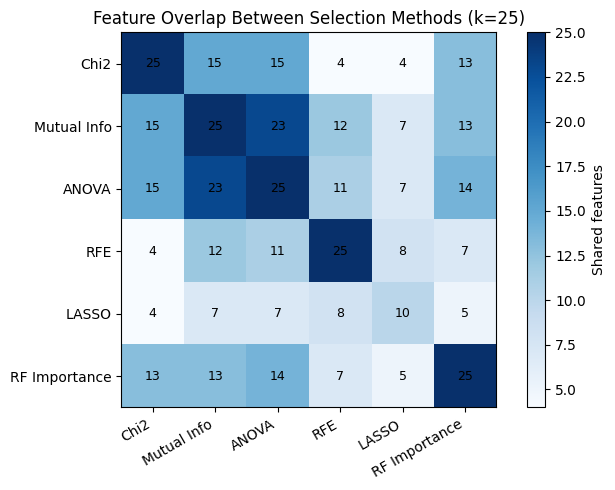

In [23]:
# ── 3.3 Overlap heatmap ───────────────────────────────────────────────────
methods   = list(top_features.keys())
n_methods = len(methods)
overlap   = np.zeros((n_methods, n_methods), dtype=int)

for i, m1 in enumerate(methods):
    for j, m2 in enumerate(methods):
        overlap[i, j] = len(top_features[m1] & top_features[m2])

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(overlap, cmap='Blues')
ax.set_xticks(range(n_methods)); ax.set_xticklabels(methods, rotation=30, ha='right')
ax.set_yticks(range(n_methods)); ax.set_yticklabels(methods)
for i in range(n_methods):
    for j in range(n_methods):
        ax.text(j, i, str(overlap[i, j]), ha='center', va='center', fontsize=9)
plt.colorbar(im, ax=ax, label='Shared features')
ax.set_title(f"Feature Overlap Between Selection Methods (k={K_FEATURES})")
plt.tight_layout()
plt.show()

In [24]:
# ── 3.4 Summary table — best model per method ─────────────────────────────
summary = {
    "Raw"              : results_raw,
    "PCA"              : results_pca,
    "Chi2 (Filter)"    : results_chi2,
    "MI (Filter)"      : results_mi,
    "ANOVA (Filter)"   : results_anova,
    "RFE (Wrapper)"    : results_rfe,
    "LASSO (Embedded)" : results_lasso,
    "RF Imp (Embedded)": results_rf_emb,
}

rows = []
for method, df_res in summary.items():
    best = df_res["Accuracy"].idxmax()
    rows.append({
        "Method"      : method,
        "Best Model"  : best,
        "Accuracy"    : df_res.loc[best, "Accuracy"],
        "F1"          : df_res.loc[best, "F1"],
        
    })

summary_df = pd.DataFrame(rows)
print(summary_df.to_string(index=False))

           Method Best Model  Accuracy       F1
              Raw Linear SVM  1.000000 1.000000
              PCA Linear SVM  1.000000 1.000000
    Chi2 (Filter)    RBF SVM  0.980392 0.985075
      MI (Filter) Linear SVM  1.000000 1.000000
   ANOVA (Filter) Linear SVM  1.000000 1.000000
    RFE (Wrapper) Linear SVM  1.000000 1.000000
 LASSO (Embedded) Linear SVM  1.000000 1.000000
RF Imp (Embedded) Linear SVM  1.000000 1.000000


---
## STEP 4 — Smart Feature Combinations
Goal: find the smallest set of features that preserves the best accuracy.

In [25]:
# ── 4.1 Feature frequency ranking (vote across all filter/embedded methods) ─
vote_features = Counter(f for s in all_sets for f in s)
ranked_features = [f for f, _ in vote_features.most_common()]

print("Feature vote ranking (most voted first):")
for f, cnt in vote_features.most_common(20):
    print(f"  {f}: {cnt} votes")

Feature vote ranking (most voted first):
  MZ245.8296: 6 votes
  MZ245.24466: 6 votes
  MZ246.12233: 5 votes
  MZ244.95245: 5 votes
  MZ245.53704: 5 votes
  MZ262.18857: 5 votes
  MZ435.07512: 5 votes
  MZ417.73207: 4 votes
  MZ464.36174: 4 votes
  MZ246.70832: 4 votes
  MZ247.00158: 4 votes
  MZ247.295: 4 votes
  MZ434.68588: 4 votes
  MZ434.29682: 4 votes
  MZ247.88239: 3 votes
  MZ244.36855: 3 votes
  MZ247.58861: 3 votes
  MZ244.66041: 3 votes
  MZ246.41524: 3 votes
  MZ418.11364: 3 votes


Using best model: Linear SVM (from Raw)


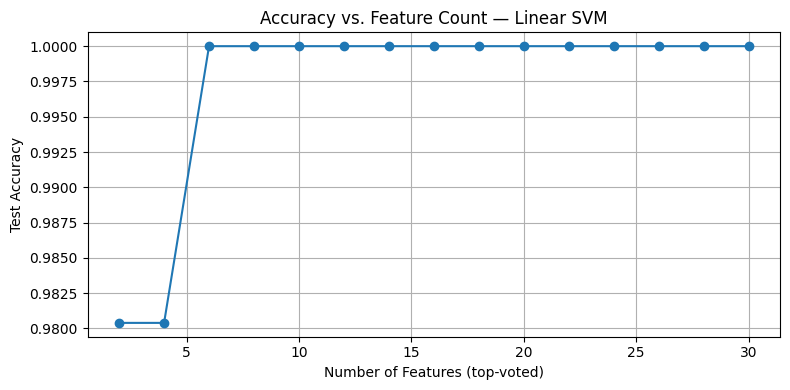


Best combination: 6 features → Accuracy = 1.0000


In [26]:
# ── 4.2 Incremental accuracy curve ────────────────────────────────────────
# Use the best model found in Step 3 (adjust model_name if needed)
best_method_row = summary_df.loc[summary_df["Accuracy"].idxmax()]
best_model_name = best_method_row["Best Model"]
print(f"Using best model: {best_model_name} (from {best_method_row['Method']})")

step_sizes = list(range(2, min(len(ranked_features) + 1, 31), 2))
acc_curve  = []

# Get column indices from the original feature list
all_feature_names = list(X_train.columns)

for k in step_sizes:
    sel_feats = ranked_features[:k]
    idx = [all_feature_names.index(f) for f in sel_feats if f in all_feature_names]
    if len(idx) < 2:
        acc_curve.append(np.nan)
        continue
    Xtr = X_train_clean[:, idx]
    Xte = X_test_scaled[:, idx]
    m   = models[best_model_name]
    m.fit(Xtr, y_train_clean)
    acc = accuracy_score(y_test, m.predict(Xte))
    acc_curve.append(acc)

plt.figure(figsize=(8, 4))
plt.plot(step_sizes, acc_curve, marker='o')
plt.xlabel("Number of Features (top-voted)")
plt.ylabel("Test Accuracy")
plt.title(f"Accuracy vs. Feature Count — {best_model_name}")
plt.grid(True)
plt.tight_layout()
plt.show()

best_k   = step_sizes[int(np.argmax(acc_curve))]
best_acc = max(acc_curve)
print(f"\nBest combination: {best_k} features → Accuracy = {best_acc:.4f}")

In [27]:
# ── 4.3 Evaluate all models on the optimal feature subset ─────────────────
best_k = 2  # Use the 2 most common (highest-voted) features
optimal_feats = ranked_features[:best_k]
opt_idx = [all_feature_names.index(f) for f in optimal_feats if f in all_feature_names]

X_train_opt = X_train_clean[:, opt_idx]
X_test_opt  = X_test_scaled[:, opt_idx]

print("=" * 60)
print(f"STEP 4 — Smart Combination: top-{best_k} voted features")
print("=" * 60)
results_opt = evaluate_models(X_train_opt, y_train_clean, X_test_opt, y_test)

STEP 4 — Smart Combination: top-2 voted features


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1271: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 4.
  warnings.warn(


  Linear SVM               : Acc=0.9804  F1=0.9851
  RBF SVM                  : Acc=0.9804  F1=0.9851
  Logistic Regression      : Acc=0.9804  F1=0.9851
  Random Forest            : Acc=0.9804  F1=0.9851
  Gradient Boosting        : Acc=0.9412  F1=0.9552
  Extra Trees              : Acc=0.9804  F1=0.9851
  KNN                      : Acc=0.9804  F1=0.9851
  AdaBoost                 : Acc=0.9804  F1=0.9851
  Ridge                    : Acc=0.9804  F1=0.9851
  Naive Bayes              : Acc=0.9804  F1=0.9851


---
## Final Summary & Comparison

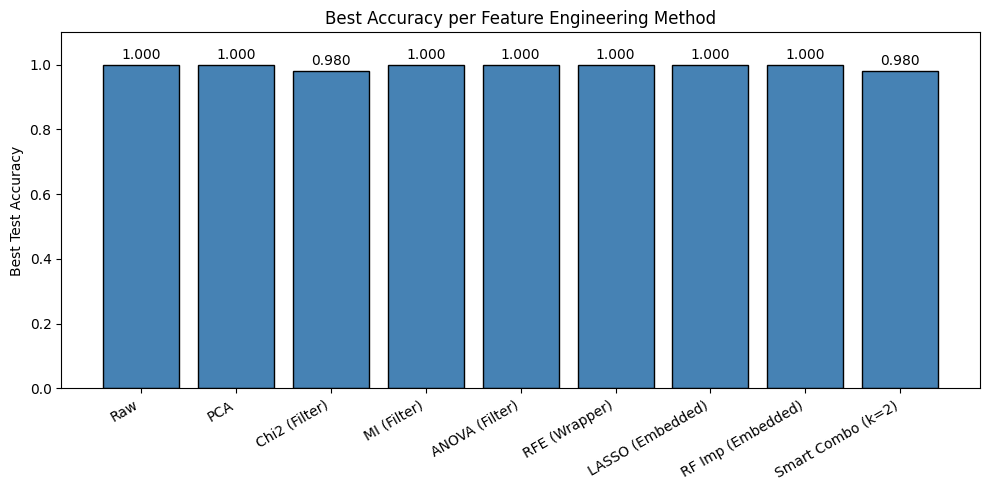


FINAL SUMMARY TABLE
           Method Best Model  Accuracy     F1
              Raw Linear SVM    1.0000 1.0000
              PCA Linear SVM    1.0000 1.0000
      MI (Filter) Linear SVM    1.0000 1.0000
   ANOVA (Filter) Linear SVM    1.0000 1.0000
    RFE (Wrapper) Linear SVM    1.0000 1.0000
RF Imp (Embedded) Linear SVM    1.0000 1.0000
 LASSO (Embedded) Linear SVM    1.0000 1.0000
    Chi2 (Filter)    RBF SVM    0.9804 0.9851
Smart Combo (k=2) Linear SVM    0.9804 0.9851


In [28]:
# ── Bar chart: best accuracy per pipeline stage ───────────────────────────
summary[f"Smart Combo (k={best_k})"] = results_opt

labels = list(summary.keys())
best_accs = [df_res["Accuracy"].max() for df_res in summary.values()]

plt.figure(figsize=(10, 5))
bars = plt.bar(labels, best_accs, color='steelblue', edgecolor='black')
plt.bar_label(bars, fmt='%.3f', padding=2)
plt.ylim(0, 1.1)
plt.xticks(rotation=30, ha='right')
plt.ylabel("Best Test Accuracy")
plt.title("Best Accuracy per Feature Engineering Method")
plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("FINAL SUMMARY TABLE")
print("=" * 60)
final_rows = []
for method, df_res in summary.items():
    best = df_res["Accuracy"].idxmax()
    final_rows.append({
        "Method"     : method,
        "Best Model" : best,
        "Accuracy"   : round(df_res.loc[best, "Accuracy"], 4),
        "F1"         : round(df_res.loc[best, "F1"], 4),
        
    })
final_df = pd.DataFrame(final_rows).sort_values("Accuracy", ascending=False)
print(final_df.to_string(index=False))